In [19]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class InverseDataset:
    def __init__(self, alpha=0.46, m=1, n=1, xmin=0, xmax=1, tmin=0, tmax=1, Nx=50, Nt=100):
        self.alpha = alpha
        self.m = m
        self.n = n

        self.x_1d = np.linspace(xmin, xmax, Nx)
        self.t_1d = np.linspace(tmin, tmax, Nt)
        self.x, self.t = np.meshgrid(self.x_1d, self.t_1d)

        self.solution = np.exp(-self.n**2 * np.pi**2 * self.alpha * self.t / self.m**2) * \
                        np.sin(self.n * np.pi * self.x / self.m)

In [20]:
class InversePINN(nn.Module):
    def __init__(self, input_size=2, hidden_size=32, num_layers=4):
        super().__init__()
        self.activation = nn.Tanh()

        # 1. Отдельная ветка для предсказания u(x,t)
        self.net_u = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            self.activation,
            *[nn.Sequential(nn.Linear(hidden_size, hidden_size), self.activation) for _ in range(num_layers - 1)],
            nn.Linear(hidden_size, 1)
        )

        # 2. Отдельная ветка для предсказания alpha(x,t)
        self.net_alpha = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            self.activation,
            *[nn.Sequential(nn.Linear(hidden_size, hidden_size), self.activation) for _ in range(num_layers - 1)],
            nn.Linear(hidden_size, 1)
        )

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        u = self.net_u(x)
        alpha = self.net_alpha(x)
        return torch.cat([u, alpha], dim=1)

In [21]:
def train_inverse_model(model, grid_tensor, u_true_tensor, epochs=3000, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)

    grid_tensor.requires_grad = True

    pbar = tqdm.tqdm(range(epochs), desc='Training Inverse PINN')
    for epoch in pbar:
        optimizer.zero_grad()

        preds = model(grid_tensor)
        u_pred = preds[:, 0:1]
        alpha_pred = preds[:, 1:2]

        loss_data = torch.mean((u_pred - u_true_tensor)**2)

        loss_pde = compute_pde_loss(u_pred, alpha_pred, grid_tensor)

        loss = loss_data * 1000 + loss_pde

        loss.backward()
        optimizer.step()
        scheduler.step()

        if epoch % 500 == 0:
            current_lr = scheduler.get_last_lr()[0]
            pbar.set_description(f"Epoch {epoch} | Loss: {loss.item():.6f} | LR: {current_lr:.6f}")

    return model

In [22]:
def run_experiment(Nx, Nt, epochs=3000):
    data = InverseDataset(alpha=0.46, Nx=Nx, Nt=Nt)

    x_flat = data.x.flatten()
    t_flat = data.t.flatten()
    u_flat = data.solution.flatten()

    grid_tensor = torch.tensor(np.vstack((x_flat, t_flat)).T, dtype=torch.float32).to(device)
    u_true_tensor = torch.tensor(u_flat, dtype=torch.float32).unsqueeze(1).to(device)

    model = InversePINN(input_size=2, hidden_size=32, num_layers=4).to(device)
    train_inverse_model(model, grid_tensor, u_true_tensor, epochs=epochs)

    with torch.no_grad():
        preds = model(grid_tensor)
        alpha_pred = preds[:, 1:2].cpu().numpy()

    alpha_true = 0.46

    rmse = np.sqrt(np.mean((alpha_pred - alpha_true)**2))
    error_percent = (rmse / alpha_true) * 100

    print(f"Сетка {Nx}x{Nt} | Среднее alpha: {np.mean(alpha_pred):.4f} | Ошибка СКЗ: {error_percent:.2f}%")

    return error_percent

grid_configs = [(50, 100), (25, 50), (10, 20), (5, 10)]

for Nx, Nt in grid_configs:
    error = run_experiment(Nx, Nt, epochs=4000)

    if error > 15.0:
        break

Epoch 3500 | Loss: 0.006490 | LR: 0.000301: 100%|██████████| 4000/4000 [04:11<00:00, 15.93it/s]


Сетка 50x100 | Среднее alpha: 0.4440 | Ошибка СКЗ: 16.98%


Epoch 3500 | Loss: 0.007045 | LR: 0.000301: 100%|██████████| 4000/4000 [04:13<00:00, 15.78it/s]


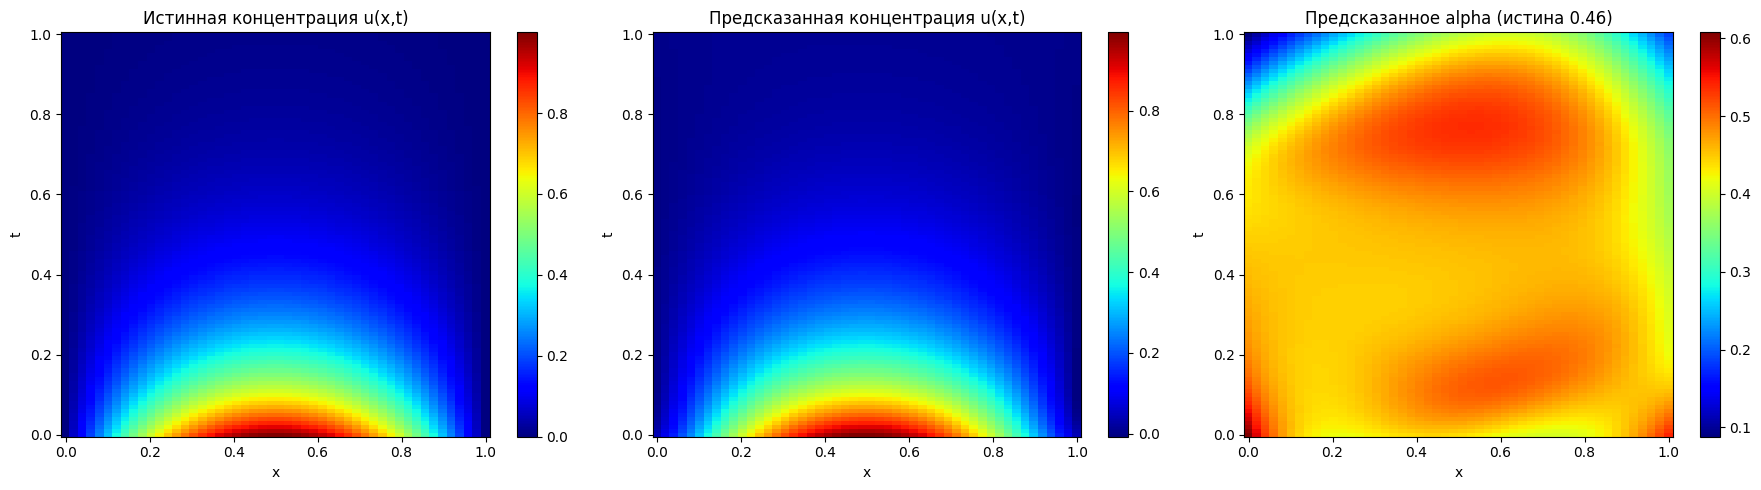

In [23]:
Nx, Nt = 50, 100
data_base = InverseDataset(alpha=0.46, Nx=Nx, Nt=Nt)

x_flat = data_base.x.flatten()
t_flat = data_base.t.flatten()
u_flat = data_base.solution.flatten()

grid_tensor = torch.tensor(np.vstack((x_flat, t_flat)).T, dtype=torch.float32).to(device)
u_true_tensor = torch.tensor(u_flat, dtype=torch.float32).unsqueeze(1).to(device)

model_base = InversePINN(input_size=2, hidden_size=32, num_layers=4).to(device)
train_inverse_model(model_base, grid_tensor, u_true_tensor, epochs=4000)

with torch.no_grad():
    preds_base = model_base(grid_tensor)
    u_pred_base = preds_base[:, 0:1].cpu().numpy().reshape(Nt, Nx)
    alpha_pred_base = preds_base[:, 1:2].cpu().numpy().reshape(Nt, Nx)


fig, ax = plt.subplots(1, 3, figsize=(18, 5))


f1 = ax[0].pcolor(data_base.x, data_base.t, data_base.solution, cmap='jet', shading='auto')
plt.colorbar(f1, ax=ax[0])
ax[0].set_title('Истинная концентрация u(x,t)')
ax[0].set_xlabel('x')
ax[0].set_ylabel('t')


f2 = ax[1].pcolor(data_base.x, data_base.t, u_pred_base, cmap='jet', shading='auto')
plt.colorbar(f2, ax=ax[1])
ax[1].set_title('Предсказанная концентрация u(x,t)')
ax[1].set_xlabel('x')
ax[1].set_ylabel('t')


f3 = ax[2].pcolor(data_base.x, data_base.t, alpha_pred_base, cmap='jet', shading='auto')
plt.colorbar(f3, ax=ax[2])
ax[2].set_title('Предсказанное alpha (истина 0.46)')
ax[2].set_xlabel('x')
ax[2].set_ylabel('t')

plt.tight_layout()
plt.show()